In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import string
from nltk.corpus import stopwords
from nltk.tokenize import TreebankWordTokenizer
from nltk.probability import FreqDist
from textblob import TextBlob
from wordcloud import WordCloud

In [64]:
# Load the dataset
df = pd.read_csv("data/cleaned_turtle_reviews.csv", usecols=["review", "summary"])

## Natural Language Processing (NLP)

### Data Cleaning for NLP

#### Transform `review` and `summary` to lowercase

In [65]:
df['review'] = df['review'].astype(str).str.lower()
df['summary'] = df['summary'].astype(str).str.lower()

#### Remove punctuation

In [66]:
df['review'] = df['review'].str.replace(f"[{string.punctuation}]", "", regex=True)

# Verify the changes
df.head()

,review,summary
0,when it comes to a dms screen the space on the...,the fact that 50% of this space is wasted on a...
1,an open letter to galeforce9\n\nyour unpainted...,another worthless dungeon master's screen from...
2,nice art nice printing why two panels are fil...,"pretty, but also pretty useless"
3,amazing buy bought it as a gift for our new dm...,five stars
4,as my review of gf9s previous screens these we...,money trap


#### Dropping Duplicates

In [67]:
# Check for duplicate student records
print('Duplicate rows:', df.duplicated().sum())

# Identify duplicates
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

Duplicate rows: 39


,review,summary
1435,as expected,five stars
1553,as expected,five stars
1651,as expected,five stars
933,awesome,five stars
1037,awesome,five stars
1383,awesome game,five stars
1577,awesome game,five stars
954,best game ever,five stars
1322,best game ever,five stars
1516,cute,five stars


In [68]:
# Drop duplicate rows
df.drop_duplicates(subset=['review', 'summary'], inplace=True)

### Tokenize

In [69]:
tokenizer = TreebankWordTokenizer()

df['review_tokens'] = df['review'].astype(str).apply(tokenizer.tokenize)
df['summary_tokens'] = df['summary'].astype(str).apply(tokenizer.tokenize)

### Create Wordcloud for `review`

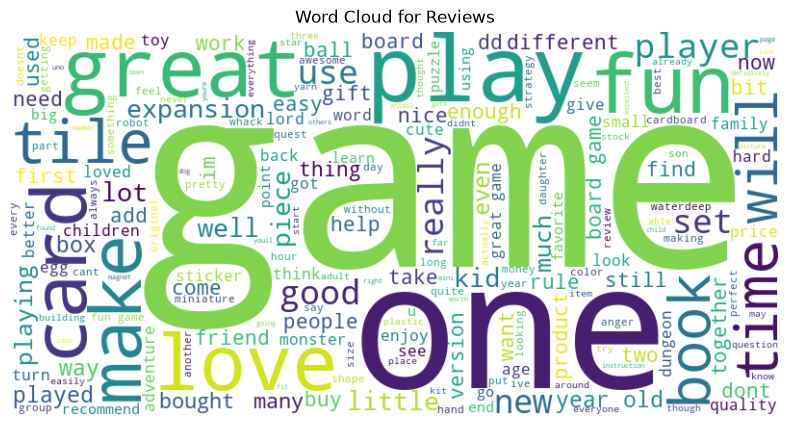

In [70]:
review_text = ' '.join([' '.join(tokens) for tokens in df['review_tokens']])

# Create WordCloud
review_wordcloud = WordCloud(width=800, height=400, background_color='white').generate(review_text)

plt.figure(figsize=(10, 5))
plt.imshow(review_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for Reviews')
plt.show()

The word cloud suggests that reviews are largely positive, with words such as 'great', 'love', 'fun' and 'good' appearing frequently.

However, som prominent words such as 'game' and 'one' are generic and add little insight. These words are not removed by standard stopword lists, as they are only uninformative in the context of game reviews. Therefore, I will remove non-alphabetic tokens, such as numbers and punctuation, along with both standard English stopwords and domain-specific stopwords (such as 'game', 'one' and 'make'), so that the more meaningful words become visible.

##### Remove alphanumeric characters and stopwords

In [71]:
# Remove non-alphabetic tokens and stopwords (standard + domain-specific)
stop_words = set(stopwords.words('english'))
domain_stopwords = {'game', 'games', 'one', 'make', 'get', 'also', 'would', 'use', 'play'}
stop_words.update(domain_stopwords)

df['clean_review_tokens'] = df['review_tokens'].apply(
    lambda tokens: [word for word in tokens if word.isalpha() and word not in stop_words]
)

df[['clean_review_tokens']].head()

,clean_review_tokens
0,"[comes, dms, screen, space, screen, absolute, ..."
1,"[open, letter, unpainted, miniatures, bad, spe..."
2,"[nice, art, nice, printing, two, panels, fille..."
3,"[amazing, buy, bought, gift, new, dm, perfect]"
4,"[review, previous, screens, completely, unnece..."


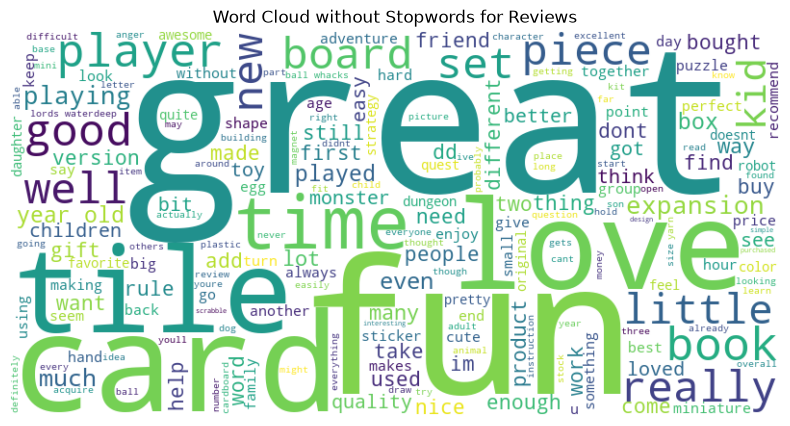

In [72]:
clean_review_words = [word for tokens in df['clean_review_tokens'] for word in tokens]

# Generate word cloud
clean_text = ' '.join(clean_review_words)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(clean_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud without Stopwords for Reviews")
plt.show()

After removing stopwords and generic domain words, 'great', 'fun' and 'love' dominate the word cloud, confirming that the reviews are largely positive. Compared to the summaries, the full reviews are more descriptive and focus on the products themselves, with words such as 'card', 'tile', 'book', 'piece', 'board' and 'expansion' appearing frequently. This suggests that card games, tile-based games and game expansions are among the most discussed product lines.

Words such as 'kid', 'children', 'year old', 'gift', 'family' and 'friend' also appear regularly, indicating that many products are bought as gifts or played together in social settings, often with or for children.

### Create Wordcloud for `summary`

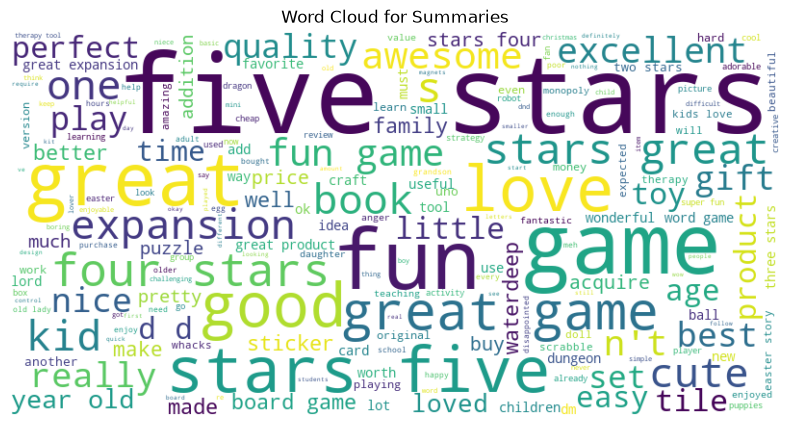

In [73]:
summary_text = ' '.join([' '.join(tokens) for tokens in df['summary_tokens']])

# Create WordCloud
summary_wordcloud = WordCloud(width=800, height=400, background_color='white').generate(summary_text)

plt.figure(figsize=(10, 5))
plt.imshow(summary_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for Summaries')
plt.show()

Words such as 'five', 'stars', 'fun', 'great' and 'good' dominate the word cloud, suggesting that the summaries are highly positive and focus mainly on praise or star ratings. Compared to the full reviews, the summaries are shorter and more direct, often consisting of a single word or short phrase such as 'great game' or 'fun'.

### Frequency Distribution and Polarity

#### Create Frequency Distribution

In [74]:
# Flatten the list of all tokens in reviews
all_review_words = [word for tokens in df['review_tokens'] for word in tokens]

# Frequency distribution
freq_dist = FreqDist(all_review_words)
freq_dist.most_common(10)  # View top 10

[('the', 5451),
 ('and', 3233),
 ('to', 3162),
 ('a', 3160),
 ('of', 2488),
 ('i', 2090),
 ('it', 2083),
 ('is', 1782),
 ('this', 1776),
 ('game', 1671)]

In [75]:
freq_dist_clean = FreqDist(clean_review_words)
common_words = freq_dist_clean.most_common(15)

# Display words with sentiment polarity
for word, count in common_words:
    polarity = TextBlob(word).sentiment.polarity
    print(f"{word}: Count = {count}, Polarity = {polarity}")

great: Count = 580, Polarity = 0.8
fun: Count = 552, Polarity = 0.3
like: Count = 414, Polarity = 0.0
love: Count = 323, Polarity = 0.5
really: Count = 319, Polarity = 0.2
cards: Count = 301, Polarity = 0.0
tiles: Count = 297, Polarity = 0.0
time: Count = 291, Polarity = 0.0
good: Count = 289, Polarity = 0.7
book: Count = 273, Polarity = 0.0
well: Count = 269, Polarity = 0.0
new: Count = 264, Polarity = 0.13636363636363635
little: Count = 248, Polarity = -0.1875
much: Count = 248, Polarity = 0.2
board: Count = 246, Polarity = 0.0


### Review Polarity and Sentiment

In [76]:
def generate_polarity(comment):
    '''Extract polarity score (-1 to +1) for each comment'''
    return TextBlob(comment).sentiment[0]

In [77]:
# Determine polarity of both columns. 
df['review_polarity'] = df['review'].apply(generate_polarity)
df['summary_polarity'] = df['summary'].apply(generate_polarity)

# Verify the changes
df[['review_polarity', 'summary_polarity']].head()

,review_polarity,summary_polarity
0,-0.036111,0.15
1,0.035952,-0.80
2,0.116640,0.00
3,0.578788,0.00
4,-0.316667,0.00


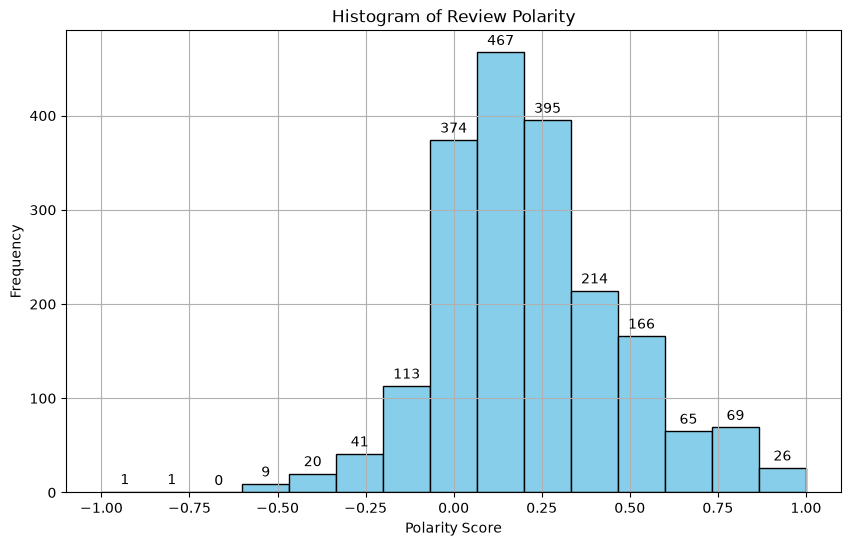

In [78]:
plt.figure(figsize=(10, 6))
counts, bins, patches = plt.hist(df['review_polarity'], bins=15,
                                 color='skyblue', edgecolor='black')

# Annotate each bar with its frequency count
plt.bar_label(patches, fmt='%.0f', padding=3)

plt.title('Histogram of Review Polarity')
plt.xlabel('Polarity Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

The review polarity scores are more spread out and form a roughly bell-shaped distribution centred slightly above 0, with a slight right skew. Most reviews are mildly positive, with the majority of scores falling between 0 and 0.5, while very few reviews reach the extremes of -1.0 or 1.0.

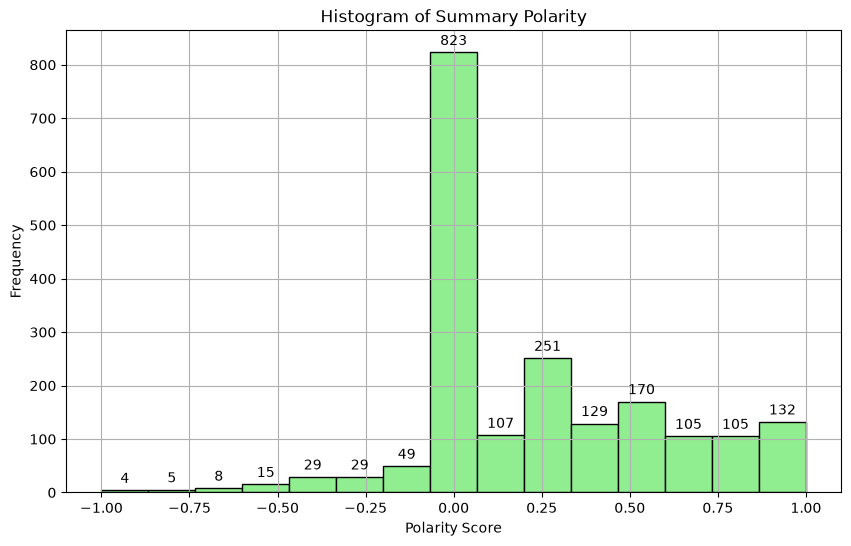

In [79]:
plt.figure(figsize=(10, 6))
counts, bins, patches = plt.hist(df['summary_polarity'], bins=15,
                                 color='lightgreen', edgecolor='black')

# Annotate each bar with its frequency count
plt.bar_label(patches, fmt='%.0f', padding=3)

plt.title('Histogram of Summary Polarity')
plt.xlabel('Polarity Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

Most summary polarity scores are close to 0, with 823 summaries falling in this range. The distribution is right-skewed, with a large number of positive scores between 0.2 and 1.0, while very few summaries have negative scores. This suggests that customers who write summaries are generally satisfied with their purchases.

### Identify Top 10 Positive & Negative `review` and `summary`

In [80]:
# Top 10 positive reviews
df[['review', 'review_polarity']].sort_values(by='review_polarity', ascending=False).head(10)

,review,review_polarity
790,perfect,1.0
1726,excellent toy to simulate thought,1.0
194,awesome gift,1.0
1967,perfect for tutoring my grandson in spelling,1.0
1177,awesome addition to my rpg gm system,1.0
1168,best set buy 2 if you have the means,1.0
524,perfect just what i ordered,1.0
1715,awesome toy,1.0
1720,it is the best thing to play with and also min...,1.0
621,wonderful for my grandson to learn the resurre...,1.0


In [81]:
# Top 10 positive summaries
df[['summary', 'summary_polarity']].sort_values(by='summary_polarity', ascending=False).head(10)

,summary,summary_polarity
599,best easter teaching tool!,1.0
418,perfect!,1.0
804,great !!,1.0
1427,excellent expansion.,1.0
1574,perfect gift,1.0
598,great easter gift!,1.0
1257,great tile set! excellent starter.,1.0
161,awesome book...,1.0
1260,master sets are best,1.0
163,he was very happy with his gift,1.0


In [82]:
# Top 10 negative reviews
df[['review', 'review_polarity']].sort_values(by='review_polarity').head(10)

,review,review_polarity
208,booo unles you are patient know how to measur...,-1.000000
182,incomplete kit very disappointing,-0.780000
1804,im sorry i just find this product to be boring...,-0.583333
364,one of my staff will be using this game soon s...,-0.550000
1524,expensive for what you get,-0.500000
117,i bought this as a christmas gift for my grand...,-0.500000
230,i found the directions difficult,-0.500000
290,instructions are complicated to follow,-0.500000
301,difficult,-0.500000
227,this was a gift for my daughter i found it di...,-0.500000


In [83]:
# Top 10 negative summaries
df[['summary', 'summary_polarity']].sort_values(by='summary_polarity').head(10)

,summary,summary_polarity
21,the worst value i've ever seen,-1.00
829,boring,-1.00
208,boring unless you are a craft person which i a...,-1.00
1166,before this i hated running any rpg campaign d...,-0.90
1,another worthless dungeon master's screen from...,-0.80
793,disappointed,-0.75
1620,disappointed,-0.75
631,disappointed.,-0.75
144,disappointed,-0.75
363,promotes anger instead of teaching calming met...,-0.70


### Sentiment Polarity Comparison: VADER vs TextBlob

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/teohuijie/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


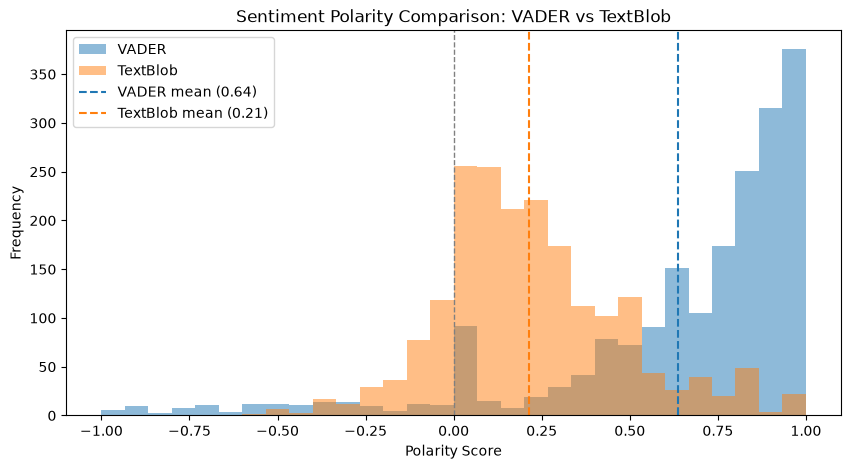

In [84]:
import numpy as np
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment.vader import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

def get_vader_score(text):
    if isinstance(text, str):
        return vader.polarity_scores(text)['compound']
    else:
        return None

# Apply to review column
df['vader_compound'] = df['review'].apply(get_vader_score)

vader_scores = df['vader_compound'].dropna()
textblob_scores = df['review_polarity'].dropna()

# Use the same bin edges for both so the bars line up
bins = np.linspace(-1, 1, 31)

plt.figure(figsize=(10, 5))
plt.hist(vader_scores, bins=bins, alpha=0.5, label='VADER')
plt.hist(textblob_scores, bins=bins, alpha=0.5, label='TextBlob')
plt.legend()
plt.title("Sentiment Polarity Comparison: VADER vs TextBlob")
plt.xlabel("Polarity Score")
plt.ylabel("Frequency")

# Mark the neutral point and each method's mean
plt.axvline(0, color='grey', linestyle='--', linewidth=1)
plt.axvline(vader_scores.mean(), color='tab:blue', linestyle='--',
            label=f'VADER mean ({vader_scores.mean():.2f})')
plt.axvline(textblob_scores.mean(), color='tab:orange', linestyle='--',
            label=f'TextBlob mean ({textblob_scores.mean():.2f})')

plt.legend()
plt.show()

In [85]:
# Classify each review as positive, negative or neutral
# VADER uses the standard ±0.05 threshold; TextBlob uses 0
df['vader_label'] = np.select(
    [df['vader_compound'] >= 0.05, df['vader_compound'] <= -0.05],
    ['Positive', 'Negative'],
    default='Neutral'
)
df['textblob_label'] = np.select(
    [df['review_polarity'] > 0, df['review_polarity'] < 0],
    ['Positive', 'Negative'],
    default='Neutral'
)

# Share of positive and negative reviews for each method
summary = pd.DataFrame({
    'VADER': df['vader_label'].value_counts(normalize=True),
    'TextBlob': df['textblob_label'].value_counts(normalize=True)
}).reindex(['Positive', 'Neutral', 'Negative']).mul(100).round(1)

print("Sentiment distribution (%):")
display(summary)

Sentiment distribution (%):


,VADER,TextBlob
Positive,88.4,80.4
Neutral,4.7,4.1
Negative,6.9,15.5


VADER compound scores are heavily concentrated at the positive end, with most scores above 0.5 and a large spike between 0.9 and 1.0. In contrast, TextBlob polarity scores are more moderate, centred around 0.2. On average, VADER scores reviews at 0.65 compared to 0.23 for TextBlob.

This difference is largely due to how each method calculates sentiment rather than one being more accurate. VADER adds up the sentiment of every word, so longer reviews with many positive words are pushed towards the maximum score of 1.0. TextBlob averages sentiment across words, so longer reviews are diluted towards 0. This is confirmed by grouping reviews by length: as reviews get longer, VADER scores increase while TextBlob scores decrease.

Despite their different scales, both methods agree on whether a review is positive or negative in about 85% of cases, and both show that the large majority of reviews are positive. VADER classifies about 89% of reviews as positive and 7% as negative, while TextBlob classifies about 81% as positive and 15% as negative.

**Insights from Natural Language Processing (NLP)**

Observations:

* Sentiment is overwhelmingly positive, with 88.4% of reviews classified as positive by VADER and 80.4% by TextBlob.
* Positive feedback centres on enjoyment, gifting and learning, often from adults buying for children or grandchildren.
* Card games, tile-based games, books and expansions are the most discussed products, with expansions suggesting repeat purchases.
* Negative feedback focuses on usability and value, such as difficult instructions, incomplete kits and poor value for money, rather than enjoyment.
* Reviews are longer and product-focused, while summaries are short and emotional. 

Recommendations:

* **Marketing team:** Promote products as gifts and learning tools for children, especially around Christmas and Easter, and target existing customers with expansions.
* **Product team:** Simplify instructions, improve quality checks to prevent incomplete kits, and redesign Dungeon Master screens to prioritise useful reference content.